# Tema 4 · Pandas y visualización: explorar un dataset real

Cargar, limpiar, resumir y graficar datos tabulares antes de modelar.

Este cuaderno es el tema 4 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/4-pandas-y-visualizacion-explorar-un-dataset-real/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

Entre 2007 y 2009, un equipo de la Estación Palmer, en la Antártida, dirigido por la bióloga Kristen Gorman, midió a 344 pingüinos de tres islas: el largo y el alto del pico, el largo de la aleta y la masa corporal. Cada pingüino pertenece a una de tres especies: Adelie, Chinstrap o Gentoo.

Imagina que te pasan solo las medidas de un pingüino, sin decirte la especie. ¿Podrías adivinarla? ¿Qué medida te serviría más?

Antes de entrenar cualquier modelo (eso lo harás desde el tema 6), hay que **mirar los datos**: saber qué columnas hay, qué falta, cómo se reparte cada medida y cómo se relacionan entre sí. A ese trabajo se le llama **análisis exploratorio**, y es lo primero que hace cualquier persona que trabaja con datos. En este tema vas a:

- guardar datos en tablas de **pandas** (`DataFrame` y `Series`) y revisarlas con `info`, `describe` y `value_counts`;
- elegir filas y columnas con `loc`, `iloc` y condiciones, agrupar con `groupby` y unir tablas con `merge`;
- encontrar **valores faltantes** y **valores atípicos**;
- dibujar con **Matplotlib** y **Seaborn** el gráfico adecuado para cada pregunta (histograma, dispersión, caja, mapa de calor, barras y línea) y escribir una conclusión a partir de él.

Necesitas lo del tema 3: arreglos de NumPy, indexación booleana y ejes.

## Actividad: mismos números, distinta historia

Antes de tocar los pingüinos, un aviso: los resúmenes (promedios, desviaciones, correlaciones) pueden esconder mucho. La **desviación estándar** es un número que dice qué tan lejos del promedio suelen estar los datos: pequeña si casi todos están cerca del promedio, grande si están muy dispersos (la calcularás en el tema 5). Arriba tienes cuatro conjuntos de once puntos y una tabla con sus números principales. Abajo, un histograma de 160 estaturas simuladas con un deslizador para el **número de intervalos**, es decir, de barras.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/4-pandas-y-visualizacion-explorar-un-dataset-real/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Mira la tabla de los cuatro conjuntos antes de ver los puntos. ¿En qué se diferencian? Escribe cómo te imaginas cada nube.
2. Pulsa «Mostrar los puntos». ¿Se parecen a lo que imaginaste? ¿En cuál de los cuatro una recta describe bien los datos?
3. En el histograma, empieza con 3 intervalos y súbelos de a uno. ¿Con cuántos aparecen dos montículos?
4. Sigue subiendo hasta 40. ¿Sigue siendo fácil ver los dos grupos, o aparece ruido?
5. Activa «Mostrar cada dato». Las rayitas son las estaturas una por una: no dependen del número de intervalos.

La lección del tema en pequeño: **los mismos números pueden contar historias distintas, y la forma de graficar puede esconder o mostrar lo importante.** Por eso siempre hay que graficar los datos, y probar más de un gráfico.

## De arreglos a tablas: Series y DataFrame

Un arreglo de NumPy guarda números de un solo tipo, y sus filas y columnas solo tienen posiciones (0, 1, 2…). Los datos reales casi nunca son así: una tabla de estudiantes tiene nombres (texto), edades (enteros) y notas (decimales), y nos gusta llamar a las columnas por su nombre. Para eso está **pandas**.

- Un **DataFrame** es una tabla: filas y columnas con nombre. Cada columna puede tener su propio tipo.
- Una **Series** es una sola columna: un arreglo de NumPy con nombre y con un **índice**, la etiqueta de cada fila.

In [ ]:
import numpy as np
import pandas as pd

# Un DataFrame se puede armar con un diccionario: una lista por columna
curso = pd.DataFrame({
    "nombre": ["Ana", "Luis", "Sara", "Iván", "Rosa"],
    "edad": [15, 16, 15, 17, 16],
    "ciudad": ["La Paz", "Sucre", "Oruro", "La Paz", "Tarija"],
    "nota": [78, 65, 91, 70, 84],
})
print(curso)
print()

# Una columna es una Series: un arreglo con nombre e índice
notas = curso["nota"]
print(type(notas).__name__, notas.shape)
print(notas.to_numpy())
print("Promedio:", notas.mean())

  nombre  edad  ciudad  nota
0    Ana    15  La Paz    78
1   Luis    16   Sucre    65
2   Sara    15   Oruro    91
3   Iván    17  La Paz    70
4   Rosa    16  Tarija    84

Series (5,)
[78 65 91 70 84]
Promedio: 77.6


La columna de la izquierda (0 a 4) es el **índice**. Por dentro, cada columna es un arreglo de NumPy: `to_numpy()` lo devuelve y todo lo del tema 3 (operar sin bucles, `mean`, `max`) sigue valiendo.

## Cargar el dataset y mirarlo

Los datos tabulares casi siempre llegan en un archivo **CSV** (*comma-separated values*): texto plano, una fila por línea y las columnas separadas por comas. En pandas se leen con `pd.read_csv("archivo.csv")`. La librería **Seaborn** trae una función, `sns.load_dataset`, que descarga de internet unos CSV de ejemplo y los lee con `read_csv`. La usamos para los pingüinos, publicados por Allison Horst, Alison Hill y Kristen Gorman con los datos de la Estación Palmer.

Las columnas vienen en inglés. Las renombramos con `rename` y traducimos los valores de la columna del sexo con `map`; los nombres de las especies y de las islas quedan como están.

In [ ]:
import seaborn as sns

# Descarga el CSV la primera vez: necesita internet
pinguinos = sns.load_dataset("penguins")

pinguinos = pinguinos.rename(columns={
    "species": "especie",
    "island": "isla",
    "bill_length_mm": "pico_largo_mm",
    "bill_depth_mm": "pico_alto_mm",
    "flipper_length_mm": "aleta_mm",
    "body_mass_g": "masa_g",
    "sex": "sexo",
})
# map cambia cada valor según el diccionario
pinguinos["sexo"] = pinguinos["sexo"].map(
    {"Male": "macho", "Female": "hembra"})

print(pinguinos.shape)
print(pinguinos.head())

(344, 7)
  especie       isla  pico_largo_mm  pico_alto_mm  aleta_mm  masa_g    sexo
0  Adelie  Torgersen           39.1          18.7     181.0  3750.0   macho
1  Adelie  Torgersen           39.5          17.4     186.0  3800.0  hembra
2  Adelie  Torgersen           40.3          18.0     195.0  3250.0  hembra
3  Adelie  Torgersen            NaN           NaN       NaN     NaN     NaN
4  Adelie  Torgersen           36.7          19.3     193.0  3450.0  hembra


`shape` funciona igual que en NumPy: 344 filas (pingüinos) y 7 columnas. `head()` muestra las primeras cinco filas. Ya se ve algo raro: a la fila 3 le faltan todas las medidas. `NaN` (*not a number*) es la forma de pandas de decir «no hay dato».

Tres órdenes dan el primer panorama de cualquier tabla nueva. `info()` dice el tipo de cada columna y cuántos valores no faltan:

In [ ]:
pinguinos.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   especie        344 non-null    str    
 1   isla           344 non-null    str    
 2   pico_largo_mm  342 non-null    float64
 3   pico_alto_mm   342 non-null    float64
 4   aleta_mm       342 non-null    float64
 5   masa_g         342 non-null    float64
 6   sexo           333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 25.0 KB


Hay dos clases de columnas:

- **Numéricas** (`float64`, `int64`): medidas con las que se puede sacar un promedio.
- **Categóricas**: etiquetas como la especie, la isla o el sexo. En Colab aparecen como `object`, que en pandas quiere decir texto (en la salida de arriba, hecha con pandas 3, aparecen como `str`). Más adelante vas a ver una tercera clase, las **fechas** (`datetime64`).

En la columna de los conteos ya se ve que faltan datos: 342 medidas de 344, y solo 333 sexos. `describe()` resume las columnas numéricas y `value_counts()` cuenta cuántas veces aparece cada categoría:

In [ ]:
print(pinguinos.describe().round(1))
print()
print(pinguinos["especie"].value_counts())

       pico_largo_mm  pico_alto_mm  aleta_mm  masa_g
count          342.0         342.0     342.0   342.0
mean            43.9          17.2     200.9  4201.8
std              5.5           2.0      14.1   802.0
min             32.1          13.1     172.0  2700.0
25%             39.2          15.6     190.0  3550.0
50%             44.4          17.3     197.0  4050.0
75%             48.5          18.7     213.0  4750.0
max             59.6          21.5     231.0  6300.0

especie
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


`describe` da, por columna, la cantidad de datos, el promedio (`mean`), la desviación estándar (`std`, qué tan lejos del promedio suelen estar los datos), el mínimo, los **cuartiles** y el máximo. El 25 % es el **primer cuartil**: un cuarto de los pingüinos tiene un valor menor que ese. El 50 % es la **mediana** y el 75 %, el tercer cuartil. La masa va de 2,7 a 6,3 kg, y el promedio, 4,2 kg, mezcla tres especies muy distintas, como vas a ver.

## Elegir filas y columnas

Hay dos maneras de señalar partes de una tabla:

- `loc[filas, columnas]` usa **etiquetas**: el índice de la fila y el nombre de la columna. Un rango como `0:2` **incluye** el final.
- `iloc[filas, columnas]` usa **posiciones**, como en NumPy. El rango `0:2` **no incluye** el final.

Para filtrar filas se usa una condición, igual que la indexación booleana del tema 3: `pinguinos["masa_g"] > 5500` es una Series de `True` y `False`, y entre corchetes deja solo las filas con `True`.

In [ ]:
print(pinguinos.loc[0, "especie"])
print(pinguinos.loc[0:2, ["especie", "masa_g"]])
print(pinguinos.iloc[0:2, 0:3])

# Filtrar con una condición
pesados = pinguinos[pinguinos["masa_g"] > 5500]
print(len(pesados), "pingüinos pesan más de 5,5 kg:")
print(pesados["especie"].value_counts())

# Varias condiciones: & (y), | (o), cada una entre paréntesis
dream = pinguinos[(pinguinos["isla"] == "Dream")
                  & (pinguinos["aleta_mm"] > 200)]
print(len(dream), "pingüinos de Dream con aleta de más de 200 mm")

Adelie
  especie  masa_g
0  Adelie  3750.0
1  Adelie  3800.0
2  Adelie  3250.0
  especie       isla  pico_largo_mm
0  Adelie  Torgersen           39.1
1  Adelie  Torgersen           39.5
28 pingüinos pesan más de 5,5 kg:
especie
Gentoo    28
Name: count, dtype: int64
22 pingüinos de Dream con aleta de más de 200 mm


Los pingüinos de más de 5,5 kg son todos de la misma especie: primera pista para la pregunta del tema.

## Valores faltantes

Antes de calcular nada hay que saber qué falta. `isna()` da una tabla de `True` y `False` (`True` donde falta el dato) y, como `True` vale 1, `sum()` cuenta los faltantes de cada columna:

In [ ]:
print(pinguinos.isna().sum())

medidas = ["pico_largo_mm", "pico_alto_mm", "aleta_mm", "masa_g"]
# any(axis=1): True en las filas con al menos un faltante
sin_medidas = pinguinos[pinguinos[medidas].isna().any(axis=1)]
print(sin_medidas[["especie", "isla"] + medidas])

especie           0
isla              0
pico_largo_mm     2
pico_alto_mm      2
aleta_mm          2
masa_g            2
sexo             11
dtype: int64
    especie       isla  pico_largo_mm  pico_alto_mm  aleta_mm  masa_g
3    Adelie  Torgersen            NaN           NaN       NaN     NaN
339  Gentoo     Biscoe            NaN           NaN       NaN     NaN


Dos pingüinos no tienen ninguna medida: no sirven para estudiar medidas, así que los sacamos con `dropna`. A otros nueve les falta solo el sexo; esos los dejamos, porque sus medidas sí sirven. Borrar todas las filas con algún faltante tira información útil, y **rellenar** un faltante con un valor inventado (por ejemplo, el promedio) puede cambiar las conclusiones. Lo correcto depende de la pregunta, pero siempre hay que decir qué se hizo.

In [ ]:
pinguinos = pinguinos.dropna(subset=medidas)
print(pinguinos.shape)
print("Sin sexo anotado:", pinguinos["sexo"].isna().sum())

(342, 7)
Sin sexo anotado: 9


## Agrupar y resumir: groupby

La pregunta «¿cuánto pesa en promedio cada especie?» tiene tres pasos: **separar** la tabla por especie, **aplicar** un resumen (el promedio) a cada parte y **juntar** los resultados. `groupby` hace los tres:

In [ ]:
por_especie = pinguinos.groupby("especie")
print(por_especie["masa_g"].mean().round(0))
print()
# agg aplica varios resúmenes a la vez
print(por_especie[["aleta_mm", "masa_g"]].agg(["mean", "std"]).round(1))
print()
# Cuántos pingüinos hay de cada especie en cada isla
print(pinguinos.groupby(["especie", "isla"]).size())

especie
Adelie       3701.0
Chinstrap    3733.0
Gentoo       5076.0
Name: masa_g, dtype: float64

          aleta_mm       masa_g       
              mean  std    mean    std
especie                               
Adelie       190.0  6.5  3700.7  458.6
Chinstrap    195.8  7.1  3733.1  384.3
Gentoo       217.2  6.5  5076.0  504.1

especie    isla     
Adelie     Biscoe        44
           Dream         56
           Torgersen     51
Chinstrap  Dream         68
Gentoo     Biscoe       123
dtype: int64


Los Gentoo pesan en promedio cerca de 1,4 kg más que las otras dos especies y tienen aletas unos 20 mm más largas. Adelie y Chinstrap se parecen mucho en masa y aleta. La última tabla muestra algo que el promedio general escondía: los Gentoo solo están en Biscoe, los Chinstrap solo en Dream, y los Adelie en las tres islas.

## Unir tablas: merge

Muchas veces la información está repartida en varias tablas. Supón que en otra tabla tenemos el nombre común en español y el nombre científico de cada especie. `merge` une las dos usando una columna que comparten, la **clave**: a cada pingüino le pega la fila de su especie.

In [ ]:
especies = pd.DataFrame({
    "especie": ["Adelie", "Chinstrap", "Gentoo"],
    "nombre_comun": ["pingüino de Adelia", "pingüino barbijo",
                     "pingüino papúa"],
    "cientifico": ["Pygoscelis adeliae", "Pygoscelis antarcticus",
                   "Pygoscelis papua"],
})

# how="left": quedan todas las filas de la tabla de la izquierda
completa = pinguinos.merge(especies, on="especie", how="left")
print(completa.shape)
print(completa[["especie", "nombre_comun", "masa_g"]]
      .sample(4, random_state=0))

(342, 9)
    especie        nombre_comun  masa_g
92   Adelie  pingüino de Adelia  4450.0
280  Gentoo      pingüino papúa  5300.0
132  Adelie  pingüino de Adelia  4475.0
279  Gentoo      pingüino papúa  4200.0


La tabla unida tiene las mismas 342 filas y dos columnas más. Con `how="left"`, un pingüino cuya especie no estuviera en la tabla `especies` quedaría con `NaN` en las columnas nuevas; con `how="inner"`, desaparecería. Lo vas a probar en los ejercicios.

## Graficar: la figura y los ejes

**Matplotlib** dibuja en dos niveles: la **figura** (`fig`) es la hoja completa y los **ejes** (`ax`) son cada gráfico dentro de ella, con su eje x, su eje y y su título. `plt.subplots()` crea las dos cosas, y luego se dibuja llamando a métodos de `ax`.

Empezamos por la pregunta más simple: ¿cómo se reparte el largo de las aletas? Para eso sirve un **histograma**: divide el rango de valores en intervalos y dibuja una barra con la cantidad de datos que cae en cada uno.

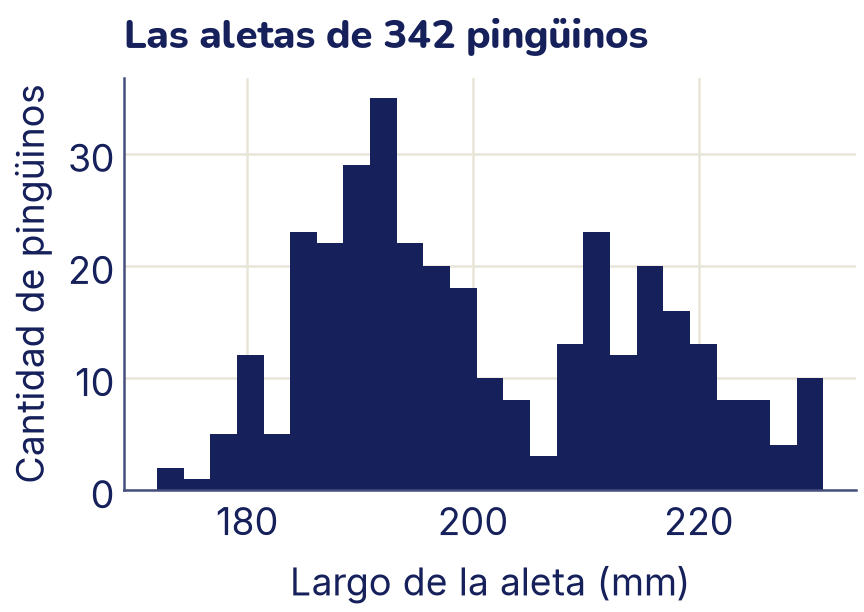

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.hist(pinguinos["aleta_mm"], bins=25, color="C0")
ax.set_xlabel("Largo de la aleta (mm)")
ax.set_ylabel("Cantidad de pingüinos")
ax.set_title("Las aletas de 342 pingüinos")
plt.show()

El histograma tiene **dos montículos**: una distribución así se llama **bimodal**, y casi siempre indica que hay dos grupos mezclados. ¿Qué grupos? Una figura puede tener varios ejes: con `plt.subplots(3, 1)` creamos tres, uno debajo del otro, y con un bucle sobre `groupby` dibujamos una especie en cada uno. Recorrer un `groupby` da, en cada vuelta, el nombre del grupo y su tabla; con `zip` los emparejamos con cada eje.

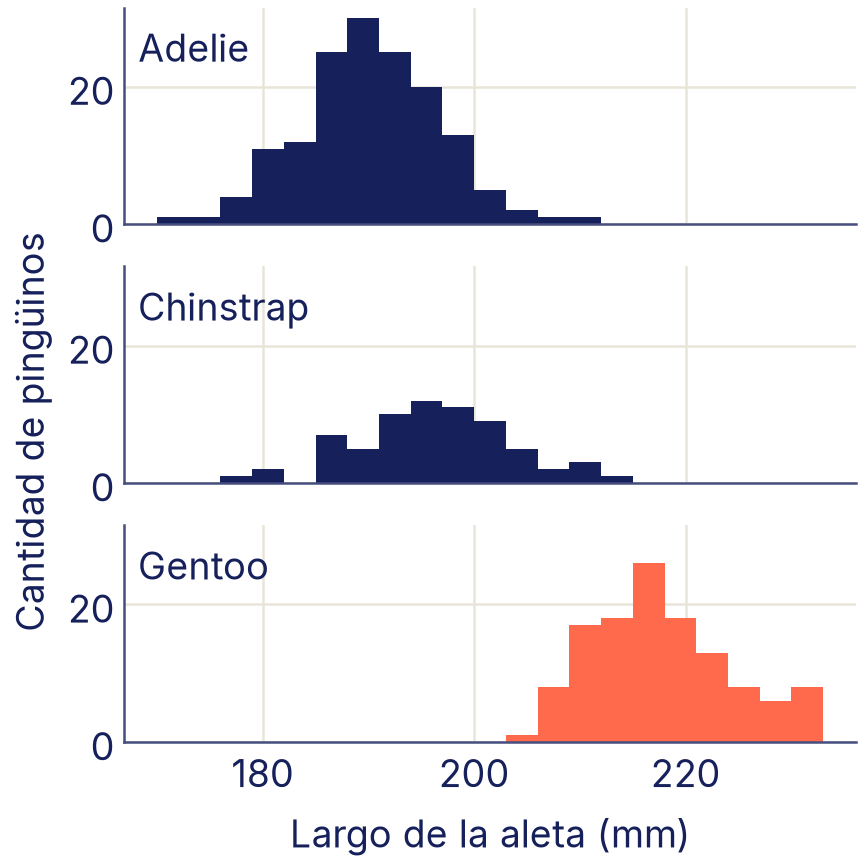

In [ ]:
fig, ejes = plt.subplots(3, 1, figsize=(4.8, 4.8), sharex=True,
                         sharey=True)
intervalos = range(170, 236, 3)    # los mismos en los tres
for ax, (especie, grupo) in zip(ejes, pinguinos.groupby("especie")):
    color = "C1" if especie == "Gentoo" else "C0"
    ax.hist(grupo["aleta_mm"], bins=intervalos, color=color)
    ax.text(0.02, 0.75, especie, transform=ax.transAxes)
ejes[-1].set_xlabel("Largo de la aleta (mm)")
fig.supylabel("Cantidad de pingüinos", fontsize=15)
plt.show()

El montículo de la derecha son los Gentoo. Adelie y Chinstrap tienen aletas parecidas y forman juntos el montículo de la izquierda. Fíjate en dos detalles del código: los tres ejes comparten la escala (`sharex`, `sharey`) y los mismos intervalos, porque si no, comparar sería engañoso.

## Dispersión: la relación entre dos medidas

Para saber cómo se relacionan dos medidas numéricas se usa un **gráfico de dispersión**: un punto por pingüino. Aquí entra **Seaborn**, una librería construida sobre Matplotlib que entiende los DataFrame: le pasas la tabla y los nombres de las columnas, y con `hue` colorea por una categoría. Con `palette` elegimos el color de cada especie y con `style`, la forma del punto, para que se distingan también sin color.

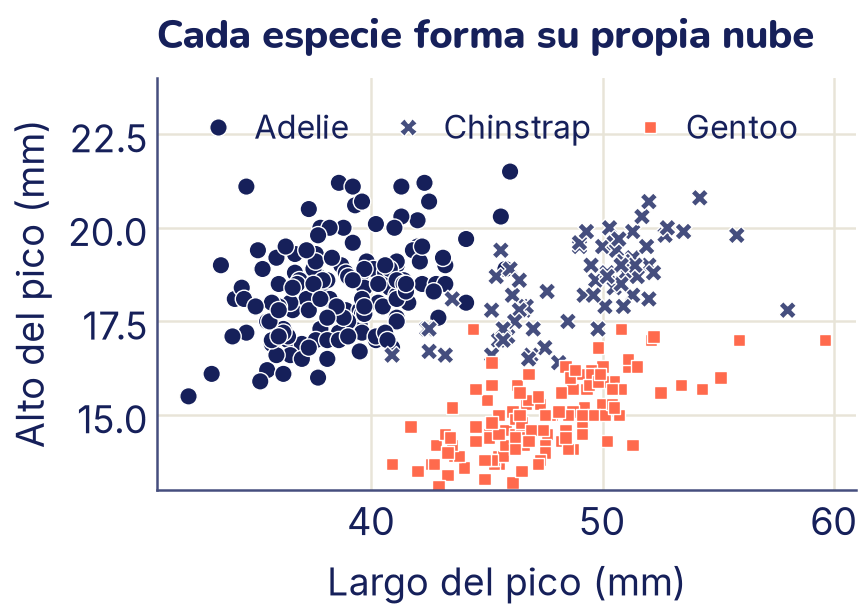

In [ ]:
colores = {"Adelie": "C0", "Chinstrap": "C2", "Gentoo": "C1"}
ax = sns.scatterplot(data=pinguinos, x="pico_largo_mm",
                     y="pico_alto_mm", hue="especie",
                     style="especie", palette=colores)
ax.set_xlabel("Largo del pico (mm)")
ax.set_ylabel("Alto del pico (mm)")
ax.set_title("Cada especie forma su propia nube")
# Un poco de espacio arriba para la leyenda, en una sola fila
# Solo para dibujar:
ax.set_ylim(13, 24)
ax.legend(title=None, fontsize=13, ncols=3, loc="upper left",
          columnspacing=0.8, handletextpad=0.1)
plt.show()

Esta figura responde la pregunta del tema: con solo dos medidas del pico, las tres especies quedan casi separadas. Adelie tiene el pico corto y alto; Chinstrap, largo y alto; Gentoo, largo y bajo. Un modelo que clasifique pingüinos (tema 8) va a tener muy fácil esta tarea. El histograma de las aletas no separaba a Adelie de Chinstrap; el pico, sí.

## Diagrama de caja y valores atípicos

Un **diagrama de caja** resume una medida con cinco números y sirve para comparar grupos. La caja va del primer al tercer cuartil y la raya del medio es la mediana. La altura de la caja es el **rango intercuartílico**, RIC = Q3 − Q1. Los bigotes llegan hasta el dato más extremo que no está demasiado lejos de la caja, y los puntos que quedan fuera se marcan como **atípicos**. La regla más usada:

$$\text{atípico si} \quad x < {Q}_{1} - 1,5 \cdot \text{RIC} \quad \text{o} \quad x > {Q}_{3} + 1,5 \cdot \text{RIC}$$

Atípicos con todos juntos: 0
       especie   isla  masa_g    sexo
189  Chinstrap  Dream  4800.0   macho
190  Chinstrap  Dream  2700.0  hembra


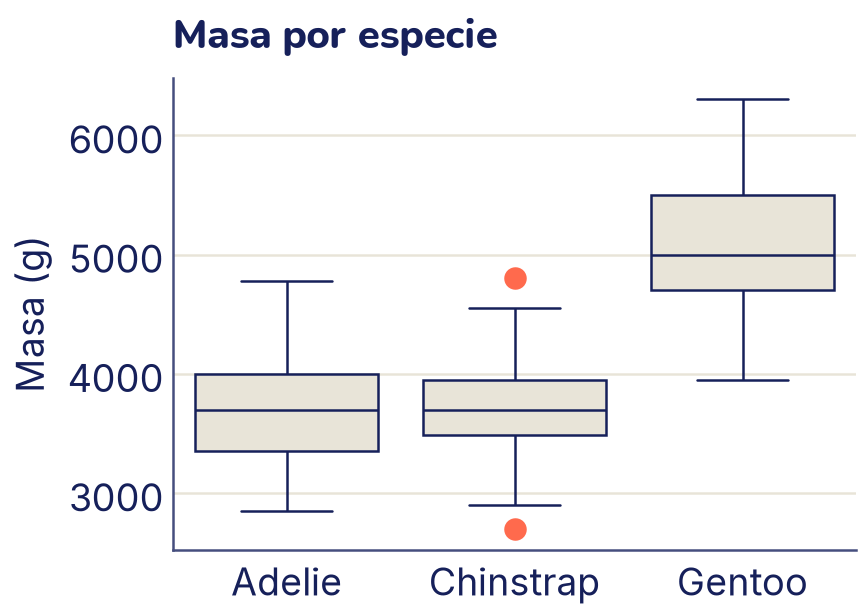

In [ ]:
def atipicos(serie):
    """True donde el valor cae fuera de los bigotes (regla 1,5·RIC)."""
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    ric = q3 - q1
    return (serie < q1 - 1.5 * ric) | (serie > q3 + 1.5 * ric)

print("Atípicos con todos juntos:", atipicos(pinguinos["masa_g"]).sum())
# transform aplica la función a cada especie por separado
es_atipico = pinguinos.groupby("especie")["masa_g"].transform(atipicos)
print(pinguinos.loc[es_atipico, ["especie", "isla", "masa_g", "sexo"]])

orden = ["Adelie", "Chinstrap", "Gentoo"]
ax = sns.boxplot(data=pinguinos, x="especie", y="masa_g", order=orden,
                 color="C3", linecolor="C0", saturation=1,
                 showfliers=False)
# Los atípicos, dibujados aparte para resaltarlos
sns.stripplot(data=pinguinos[es_atipico], x="especie", y="masa_g",
              order=orden, color="C1", size=9, jitter=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Masa (g)")
ax.set_title("Masa por especie")
plt.show()

Mirando todos los pingüinos juntos no hay ningún atípico, pero dentro de los Chinstrap hay dos: uno muy liviano y uno muy pesado **para su especie**. Ser atípico depende del grupo con que se compara.

Un atípico **no es lo mismo que un error**. Un pingüino de 4,8 kg es posible; uno de 48 kg sería un error de tipeo. Ante un atípico, primero se investiga: si es un error, se corrige o se saca; si es real, se deja y se tiene en cuenta, porque un solo valor extremo puede mover mucho un promedio (recuerda el 40 de Diego en los ejercicios del tema 2).

## Correlación y mapa de calor

La **correlación** mide qué tan bien una recta describe la relación entre dos columnas. Es un número entre −1 y 1: cerca de 1, cuando una sube la otra también; cerca de −1, cuando una sube la otra baja; cerca de 0, no hay relación lineal. `corr()` la calcula para todos los pares de columnas, y un **mapa de calor** pinta esa tabla con colores.

Lo esencial es una sola línea: `sns.heatmap(corr, annot=True)` pinta la tabla y escribe cada número en su casilla. Todo lo demás del bloque solo cambia el aspecto: armamos una paleta con `LinearSegmentedColormap`, que va del blanco a la tinta, y coloreamos según la **fuerza** de la relación (el valor absoluto, `abs()`): cuanto más oscura la casilla, más fuerte la relación, sea positiva o negativa. El signo queda escrito en cada casilla gracias a `annot`.

               pico_largo_mm  pico_alto_mm  aleta_mm  masa_g
pico_largo_mm           1.00         -0.24      0.66    0.60
pico_alto_mm           -0.24          1.00     -0.58   -0.47
aleta_mm                0.66         -0.58      1.00    0.87
masa_g                  0.60         -0.47      0.87    1.00


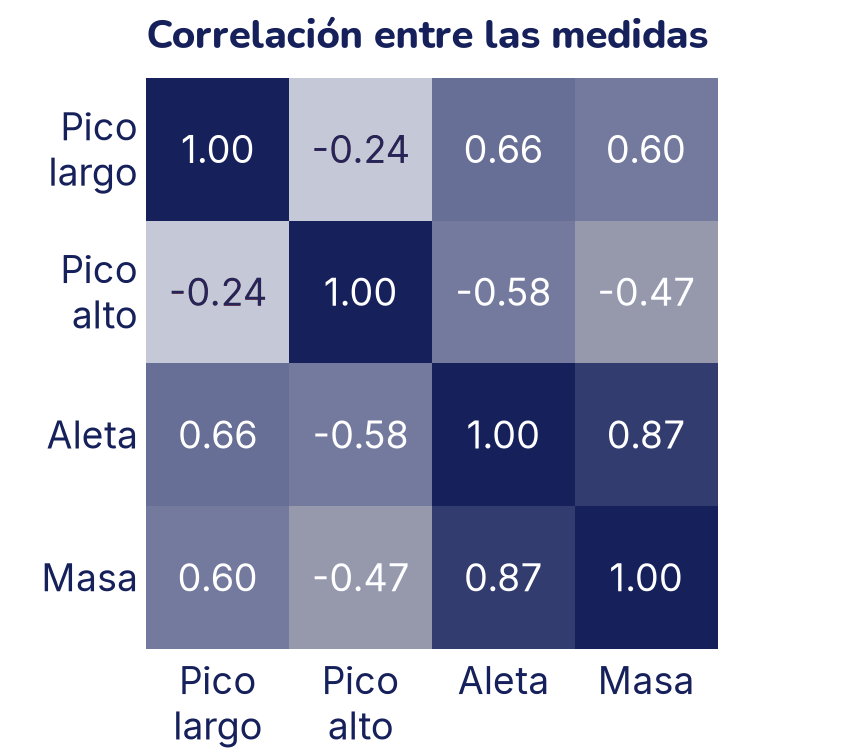

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

corr = pinguinos[medidas].corr()
print(corr.round(2))

# Solo para dibujar: una paleta propia y etiquetas cortas
# (\n parte la etiqueta en dos líneas)
nombres = ["Pico\nlargo", "Pico\nalto", "Aleta", "Masa"]
blanco_tinta = LinearSegmentedColormap.from_list("bt", ["white", "C0"])
fig, ax = plt.subplots(figsize=(4.8, 4.2))
sns.heatmap(corr.abs(), annot=corr, fmt=".2f", cmap=blanco_tinta,
            vmin=0, vmax=1, square=True, cbar=False,
            xticklabels=nombres, yticklabels=nombres, ax=ax)
ax.tick_params(axis="both", labelrotation=0)
ax.set_title("Correlación entre las medidas")
plt.show()

La relación más fuerte es entre la aleta y la masa: 0,87. Los pingüinos con aletas largas suelen pesar más. Pero **correlación no es causalidad**: las aletas largas no *hacen* pesar más a un pingüino. Las dos medidas crecen con el tamaño del animal, y el tamaño depende sobre todo de la especie. Cuando una tercera variable mueve a las otras dos, se dice que es una **variable de confusión**.

Fíjate también en el alto del pico: su correlación con las demás medidas es negativa. ¿Un pico más alto en un pingüino más chico? Otra vez la especie: los Gentoo son los más grandes y tienen el pico más bajo. Lo vas a desarmar en los ejercicios.

## Barras y líneas

Un **gráfico de barras** compara cantidades entre categorías. Los DataFrame de pandas también saben graficarse: `.plot.bar()` usa Matplotlib por dentro. Con `pd.crosstab` contamos cuántos pingüinos hay de cada especie en cada isla y apilamos las barras:

especie    Adelie  Chinstrap  Gentoo
isla                                
Biscoe         44          0     123
Dream          56         68       0
Torgersen      51          0       0


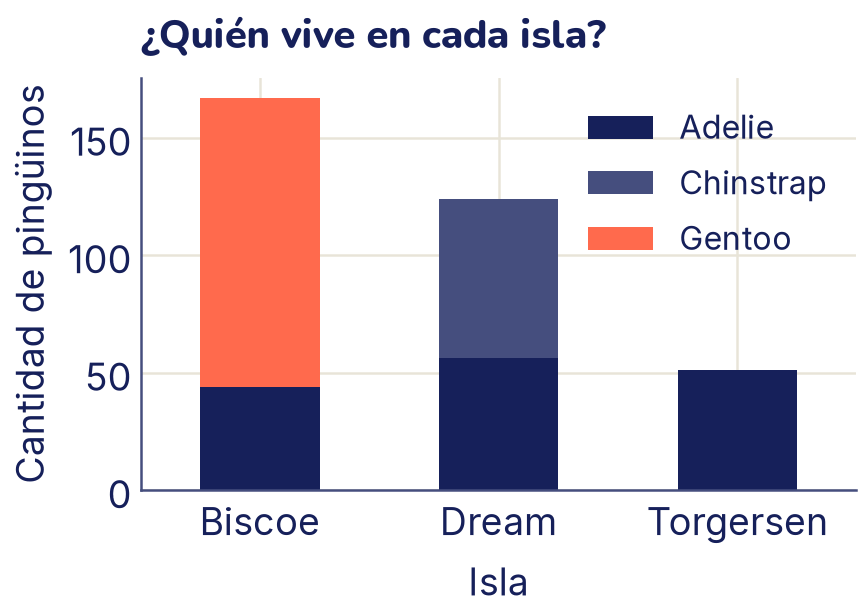

In [ ]:
conteo = pd.crosstab(pinguinos["isla"], pinguinos["especie"])
print(conteo)

ax = conteo.plot.bar(stacked=True, color=["C0", "C2", "C1"], rot=0)
ax.set_xlabel("Isla")
ax.set_ylabel("Cantidad de pingüinos")
ax.set_title("¿Quién vive en cada isla?")
ax.legend(title=None, fontsize=13)
plt.show()

Un **gráfico de línea** sirve cuando el eje x tiene un orden natural, casi siempre el **tiempo**: la línea une un mes con el siguiente. Los pingüinos no tienen fechas, así que usamos otro dataset de Seaborn: la cantidad mensual de pasajeros de vuelos internacionales entre 1949 y 1960, en miles. Para que pandas entienda el tiempo, convertimos el año y el mes en una columna de tipo **fecha** con `pd.to_datetime`. Su tipo es `datetime64` (lo que va entre corchetes, la precisión, puede cambiar según la versión de pandas).

   year month  passengers
0  1949   Jan         112
1  1949   Feb         118
2  1949   Mar         132
datetime64[us]
Mes con más pasajeros: 07/1960 con 622 mil


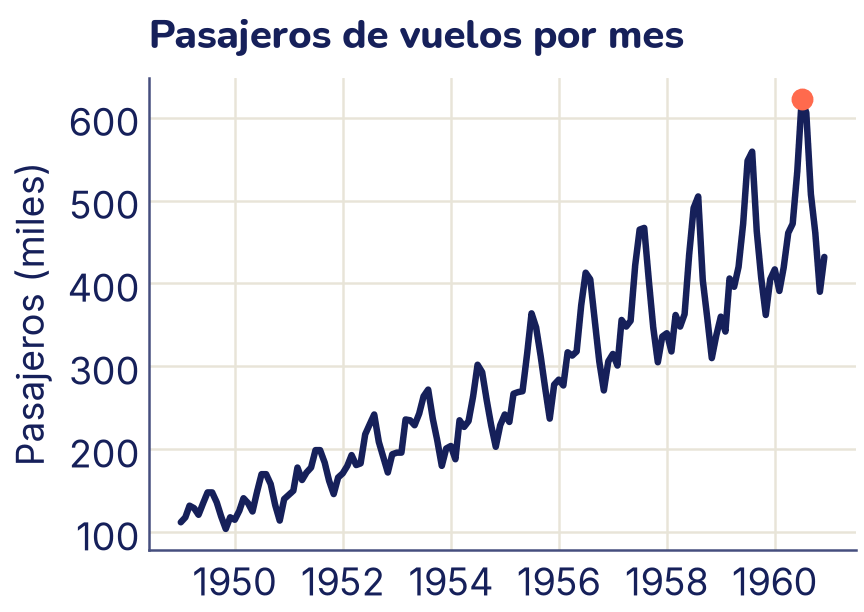

In [ ]:
vuelos = sns.load_dataset("flights")
print(vuelos.head(3))

# "1949" + "-" + "Jan" → fecha; %Y es el año y %b, el mes abreviado
texto = vuelos["year"].astype(str) + "-" + vuelos["month"].astype(str)
vuelos["fecha"] = pd.to_datetime(texto, format="%Y-%b")
print(vuelos["fecha"].dtype)

mayor = vuelos.loc[vuelos["passengers"].idxmax()]
print("Mes con más pasajeros:", mayor["fecha"].strftime("%m/%Y"),
      "con", mayor["passengers"], "mil")

fig, ax = plt.subplots()
ax.plot(vuelos["fecha"], vuelos["passengers"], color="C0")
ax.scatter(mayor["fecha"], mayor["passengers"], color="C1", s=60,
           zorder=3)
ax.set_ylabel("Pasajeros (miles)")
ax.set_title("Pasajeros de vuelos por mes")
plt.show()

La línea muestra dos cosas que una tabla de 144 números escondería: una **tendencia** (los pasajeros se multiplican por más de cuatro en doce años) y una **estacionalidad** (cada año hay un pico a mitad de año, en el verano del hemisferio norte, y el pico crece con los años). Las series de tiempo vuelven en el tema 13.

### ¿Qué gráfico para qué pregunta?

| Pregunta | Gráfico |
| --- | --- |
| ¿Cómo se reparten los valores de una medida? | Histograma |
| ¿Cómo se relacionan dos medidas? | Dispersión |
| ¿Cómo se compara una medida entre grupos? ¿Hay atípicos? | Caja |
| ¿Qué pares de medidas van juntos? | Mapa de calor de correlaciones |
| ¿Cuánto hay de cada categoría? | Barras |
| ¿Cómo cambia algo con el tiempo? | Línea |

## El cuarteto de Anscombe

En 1973, el estadístico Francis Anscombe armó cuatro conjuntos de once puntos para demostrar por qué hay que graficar. Son los de la actividad, y Seaborn los trae:

         media_x  media_y  desv_x  desv_y  correlacion
dataset                                               
I            9.0      7.5    3.32    2.03         0.82
II           9.0      7.5    3.32    2.03         0.82
III          9.0      7.5    3.32    2.03         0.82
IV           9.0      7.5    3.32    2.03         0.82


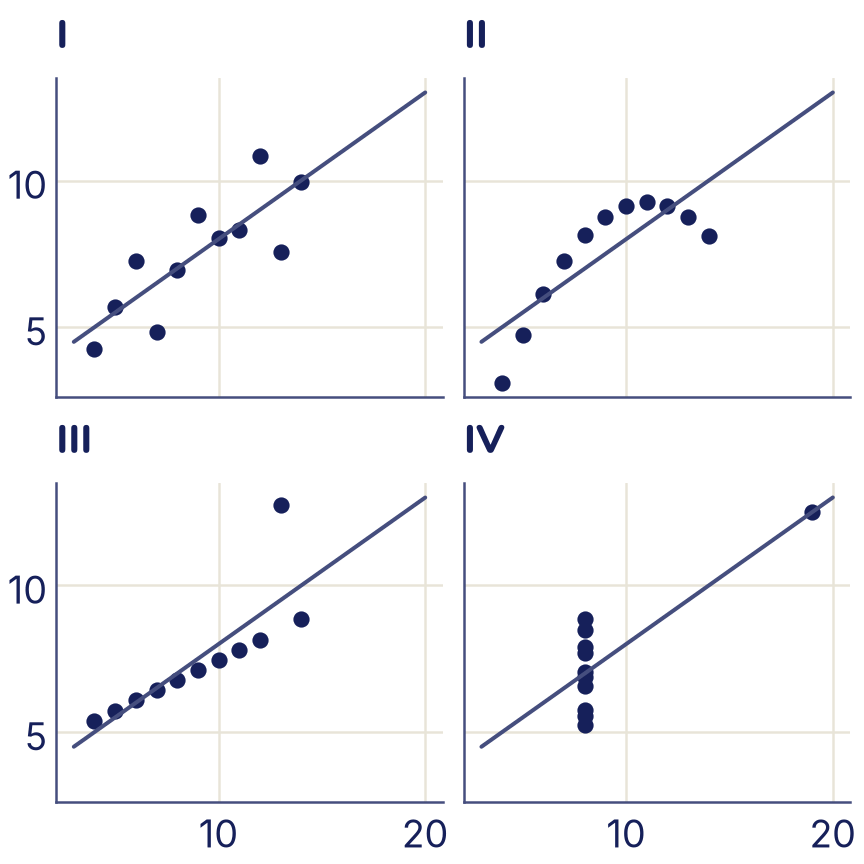

In [ ]:
anscombe = sns.load_dataset("anscombe")
resumen = anscombe.groupby("dataset").agg(
    media_x=("x", "mean"), media_y=("y", "mean"),
    desv_x=("x", "std"), desv_y=("y", "std"))
resumen["correlacion"] = [g["x"].corr(g["y"])
                          for _, g in anscombe.groupby("dataset")]
print(resumen.round(2))

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8), sharex=True,
                         sharey=True)
x_recta = np.array([3, 20])
for ax, (nombre, g) in zip(ejes.flat, anscombe.groupby("dataset")):
    ax.scatter(g["x"], g["y"], color="C0", s=30)
    # La recta que mejor se ajusta (la vas a calcular en el tema 6)
    pendiente, corte = np.polyfit(g["x"], g["y"], 1)
    ax.plot(x_recta, pendiente * x_recta + corte, color="C2",
            linewidth=1.6)
    ax.set_title(nombre)
plt.show()

Los cuatro resúmenes son prácticamente iguales, y también la recta. Pero solo en el conjunto I la recta es una buena descripción. En el II la relación es una curva; en el III un solo atípico inclina la recta; en el IV un único punto crea toda la correlación. **Ningún resumen reemplaza a mirar los datos.**

## Un análisis exploratorio en cinco preguntas

Lo que hiciste con los pingüinos es un análisis exploratorio completo. Con cualquier dataset nuevo, hazte estas cinco preguntas, en orden:

1. **¿Qué hay en la tabla?** `shape`, `head`, `info`: 344 pingüinos, 7 columnas, 4 numéricas y 3 categóricas.
2. **¿Qué falta?** `isna().sum()`: dos pingüinos sin medidas (los sacamos) y nueve sin sexo (los dejamos).
3. **¿Cómo se reparte cada medida?** `describe`, `value_counts` e histogramas: las aletas son bimodales porque los Gentoo son más grandes.
4. **¿Cómo se relacionan las medidas?** Dispersión y correlaciones: con el largo y el alto del pico las especies casi se separan; la aleta y la masa van muy juntas.
5. **¿Hay atípicos o sorpresas?** Cajas por grupo: dos Chinstrap fuera de lo común, pero reales; cada especie vive en islas distintas.

Cada respuesta termina en una **conclusión escrita**, una oración que cualquiera pueda comprobar mirando el gráfico. Un gráfico sin conclusión no le dice nada a nadie.

## Lo que aprendiste y lo que sigue

- Un **DataFrame** es una tabla con columnas de distinto tipo; cada columna es una **Series**, un arreglo de NumPy con nombre e índice.
- `info`, `describe` y `value_counts` dan el primer panorama; `isna().sum()` cuenta los **faltantes**, y la regla del **1,5·RIC** señala los **atípicos**, que hay que investigar antes de borrar.
- `loc` elige por etiqueta, `iloc` por posición, y una condición filtra filas. `groupby` separa, resume y junta; `merge` une tablas por una clave.
- Cada pregunta tiene su gráfico: histograma, dispersión, caja, mapa de calor, barras o línea. Matplotlib dibuja en una **figura** con **ejes**, y Seaborn grafica directo desde un DataFrame.
- Los resúmenes pueden esconder la forma de los datos (Anscombe), el número de intervalos cambia lo que muestra un histograma, y **correlación no es causalidad**.

En el tema 5 vas a usar estas tablas para calcular promedios, desviaciones y probabilidades con código. Desde el tema 6, cada modelo empezará con un análisis exploratorio como este.

# Ejercicios

## Antes de empezar

Los ejercicios usan lo que se definió en la teoría: `pinguinos` (ya sin las dos filas sin medidas), `medidas`, `especies`, `atipicos`, `colores` y las librerías `np`, `pd`, `plt` y `sns`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta: equivocarse primero y corregir después es como se aprende de verdad.

## Ejercicios

### 1. Diez preguntas cortas

Responde cada pregunta con una o dos líneas de pandas.

1. ¿Cuántas filas y columnas tiene `pinguinos`?
2. ¿Cuál es la aleta más larga?
3. ¿Cuántas hembras hay?
4. ¿En cuántas islas distintas vive cada especie?
5. ¿Cuál es la masa media de los machos y de las hembras?
6. ¿Cuántos Gentoo pesan menos de 4 kg?
7. ¿De qué especie e isla es el pingüino más liviano, y cuánto pesa?
8. ¿Cuál es la mediana del largo del pico de cada especie?
9. ¿Qué porcentaje de los pingüinos vive en cada isla?
10. Agrega una columna `masa_kg` con la masa en kilos. ¿Cuál es su promedio?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
# 1
print(pinguinos.shape)
# 2
print(pinguinos["aleta_mm"].max())
# 3
print((pinguinos["sexo"] == "hembra").sum())
# 4
print(pinguinos.groupby("especie")["isla"].nunique())
# 5
print(pinguinos.groupby("sexo")["masa_g"].mean().round(0))
# 6
gentoo = pinguinos[pinguinos["especie"] == "Gentoo"]
print((gentoo["masa_g"] < 4000).sum())
# 7: idxmin da la etiqueta de la fila con el valor más chico
print(pinguinos.loc[pinguinos["masa_g"].idxmin(),
                    ["especie", "isla", "masa_g"]])
# 8
print(pinguinos.groupby("especie")["pico_largo_mm"].median())
# 9: normalize=True da proporciones en lugar de conteos
print((pinguinos["isla"].value_counts(normalize=True) * 100).round(1))
# 10
pinguinos["masa_kg"] = pinguinos["masa_g"] / 1000
print(round(pinguinos["masa_kg"].mean(), 2))

<details>
<summary>Respuesta</summary>

Fíjate en el 5: `groupby` deja fuera a los nueve pingüinos sin sexo, porque `NaN` no es un grupo. Y en el 3: comparar con `==` da `False` donde falta el dato, así que esos nueve tampoco se cuentan como hembras.

</details>

### 2. Guardar y volver a leer un CSV

a) Guarda `pinguinos` en un archivo `pinguinos.csv` con `to_csv(..., index=False)`, léelo de nuevo con `pd.read_csv` y revisa la copia con `info()`. ¿Tiene las mismas filas y columnas? ¿Siguen ahí los faltantes del sexo?

b) Guárdalo otra vez, ahora **sin** `index=False`, y lee el archivo. ¿Qué columna nueva aparece?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
pinguinos.to_csv("pinguinos.csv", index=False)
copia = pd.read_csv("pinguinos.csv")
copia.info()

pinguinos.to_csv("con_indice.csv")
print(pd.read_csv("con_indice.csv").columns[:3].tolist())

<details>
<summary>Respuesta</summary>

a) La copia tiene las mismas 342 filas y 8 columnas (con `masa_kg` del ejercicio 1), y los mismos 9 faltantes en `sexo`: en el CSV un faltante es una casilla vacía, y `read_csv` lo vuelve a leer como `NaN`.

b) Sin `index=False`, el índice se guarda como una columna sin nombre, y al leerla aparece como `Unnamed: 0`. Es uno de los errores más comunes: por eso conviene guardar con `index=False`, salvo que el índice tenga información.

</details>

### 3. Los faltantes de la tabla original

Vuelve a cargar los datos sin limpiar: `crudo = sns.load_dataset("penguins")`.

a) ¿Cuántas filas tienen al menos un faltante?

b) ¿Qué porcentaje de las filas no tiene el sexo anotado?

c) Si hicieras `crudo.dropna()`, ¿cuántos pingüinos perderías? ¿Por qué en la teoría no lo hicimos así?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
crudo = sns.load_dataset("penguins")
con_faltantes = crudo.isna().any(axis=1)
print("Filas con algún faltante:", con_faltantes.sum())
print(f"Sin sexo: {crudo['sex'].isna().mean() * 100:.1f} %")
print("Filas después de dropna():", len(crudo.dropna()))

<details>
<summary>Respuesta</summary>

a) Once filas tienen algún faltante: las 11 sin sexo, que incluyen a los dos pingüinos sin ninguna medida.

b) El promedio de una columna de `True` y `False` es la proporción de `True`: el 3,2 % de las filas no tiene sexo.

c) `dropna()` sin más borra 11 pingüinos. Nueve de ellos tienen todas sus medidas, que sirven para cualquier pregunta que no use el sexo. Por eso en la teoría solo borramos las filas sin medidas, con `dropna(subset=medidas)`. La regla: borra solo lo que la pregunta necesita, y di qué borraste.

</details>

### 4. Atípicos en el largo del pico

a) Usa la función `atipicos` de la teoría para buscar valores atípicos en el largo del pico, primero mirando a todos los pingüinos juntos y después dentro de cada especie.

b) ¿Te parece un error de medición? ¿Qué harías con ese pingüino?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
pico = pinguinos["pico_largo_mm"]
print("Todos juntos:", atipicos(pico).sum())
raro = pinguinos.groupby("especie")["pico_largo_mm"].transform(atipicos)
print(pinguinos.loc[raro, ["especie", "isla", "pico_largo_mm", "sexo"]])
print(pinguinos.groupby("especie")["pico_largo_mm"]
      .describe()[["mean", "75%", "max"]].round(1))
# Los tres picos más largos de todo el dataset
print(pico.nlargest(3).tolist())

<details>
<summary>Respuesta</summary>

a) Juntos no hay atípicos; dentro de cada especie, uno: un Gentoo macho con un pico de 59,6 mm, el más largo de todo el dataset.

b) Su pico es unos 12 mm más largo que el promedio de los Gentoo, pero no es imposible: el segundo pico más largo del dataset, de un Chinstrap, mide 58 mm, apenas 1,6 mm menos. No hay razón para creer que es un error de tipeo, así que lo dejamos y, si un análisis depende mucho de él (por ejemplo, un promedio de pocos datos), lo decimos. Un atípico se investiga; no se borra solo por ser raro.

</details>

### 5. Unir tablas cuando falta una clave

Supón que la tabla de nombres se escribió incompleta y le falta la fila de Chinstrap:

In [ ]:
incompleta = especies[especies["especie"] != "Chinstrap"]
print(incompleta[["especie", "nombre_comun"]])

  especie        nombre_comun
0  Adelie  pingüino de Adelia
2  Gentoo      pingüino papúa


a) Únela a `pinguinos` con `how="left"` y con `how="inner"`. ¿Cuántas filas tiene cada resultado?

b) En la unión con `how="left"`, ¿cuántos faltantes tiene `nombre_comun`, y de qué especie son?

c) ¿Qué peligro tiene usar `how="inner"` sin revisar el resultado?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
izquierda = pinguinos.merge(incompleta, on="especie", how="left")
interna = pinguinos.merge(incompleta, on="especie", how="inner")
print("left: ", izquierda.shape)
print("inner:", interna.shape)
faltan = izquierda[izquierda["nombre_comun"].isna()]
print(faltan["especie"].value_counts())

<details>
<summary>Respuesta</summary>

a) Con `how="left"` quedan las 342 filas; con `how="inner"`, solo las 274 cuya especie está en las dos tablas.

b) Los 68 Chinstrap quedan con `NaN` en `nombre_comun`.

c) `how="inner"` borra en silencio las filas sin pareja: aquí desaparece una especie entera y nada avisa. Después de un `merge`, compara siempre la cantidad de filas con la que esperabas.

</details>

### 6. ¿Qué gráfico usarías?

Para cada pregunta, elige el gráfico y di qué columnas pondrías en cada eje.

1. ¿Los machos pesan más que las hembras en cada especie?
2. ¿Cómo se reparte el largo del pico de los Adelie?
3. ¿Hay relación entre el largo de la aleta y el largo del pico?
4. ¿Cuántos pingüinos se midieron de cada sexo?
5. ¿Qué par de medidas está más relacionado?
6. ¿Cómo cambió la cantidad de pasajeros de enero a diciembre de 1955?

<details>
<summary>Respuesta</summary>

1. **Caja**: la especie en x, la masa en y, y una caja por sexo (`hue="sexo"` en `sns.boxplot`). Compara grupos y muestra atípicos.
2. **Histograma** del largo del pico, filtrando antes a los Adelie.
3. **Dispersión**: aleta en x, pico en y, con color por especie para no mezclar grupos.
4. **Barras**: una barra por sexo con su conteo (`value_counts().plot.bar()`).
5. **Mapa de calor** de la matriz de correlación.
6. **Línea**: los meses de 1955 en x, en orden, y los pasajeros en y.

</details>

### 7. Tres gráficos engañosos

Cada gráfico de abajo lleva a una conclusión equivocada. Para cada uno, di qué conclusión sugiere, por qué engaña y escribe el código de una versión honesta.

**a)** «Los Gentoo pesan casi el triple que los Adelie».

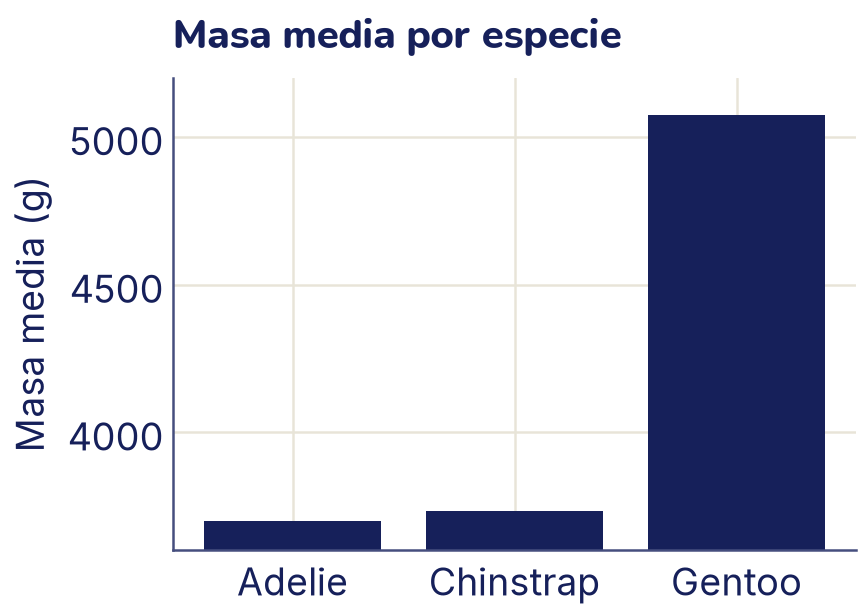

In [ ]:
masa_media = pinguinos.groupby("especie")["masa_g"].mean()
fig, ax = plt.subplots()
ax.bar(masa_media.index, masa_media, color="C0")
ax.set_ylim(3600, 5200)
ax.set_ylabel("Masa media (g)")
ax.set_title("Masa media por especie")
plt.show()

**b)** «La cantidad de pingüinos baja de isla en isla».

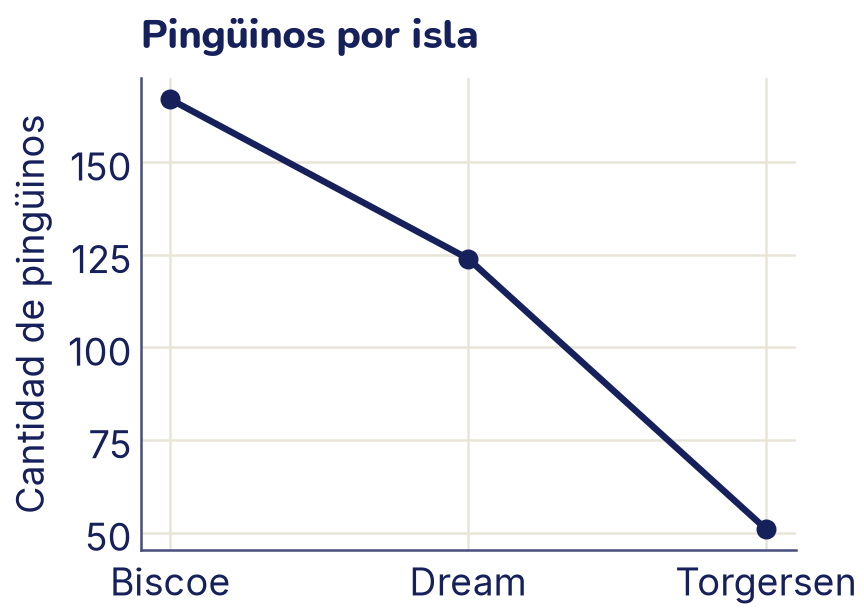

In [ ]:
por_isla = pinguinos["isla"].value_counts()
fig, ax = plt.subplots()
ax.plot(por_isla.index, por_isla, color="C0", marker="o")
ax.set_ylabel("Cantidad de pingüinos")
ax.set_title("Pingüinos por isla")
plt.show()

**c)** «A pico más largo, pico menos alto».

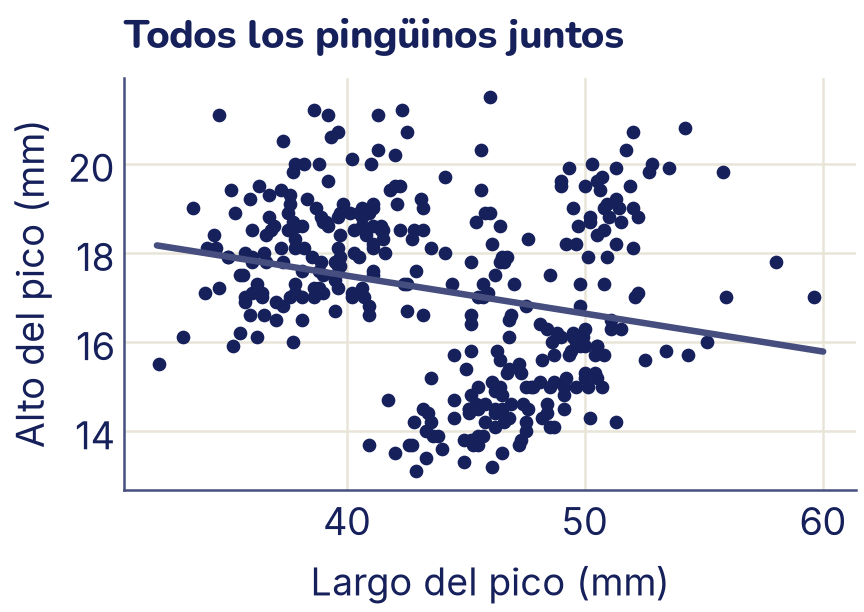

In [ ]:
fig, ax = plt.subplots()
ax.scatter(pinguinos["pico_largo_mm"], pinguinos["pico_alto_mm"],
           color="C0", s=20)
pendiente, corte = np.polyfit(pinguinos["pico_largo_mm"],
                              pinguinos["pico_alto_mm"], 1)
x_recta = np.array([32, 60])
ax.plot(x_recta, pendiente * x_recta + corte, color="C2")
ax.set_xlabel("Largo del pico (mm)")
ax.set_ylabel("Alto del pico (mm)")
ax.set_title("Todos los pingüinos juntos")
plt.show()

<details>
<summary>Respuesta</summary>

**a)** El eje y empieza en 3600 g, no en 0. El largo de una barra se lee como la cantidad, así que una diferencia de un 37 % se ve como si fuera del triple. En un gráfico de barras, el eje empieza en cero.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
print((masa_media / masa_media["Adelie"]).round(2))
fig, ax = plt.subplots()
colores_barras = ["C1" if e == "Gentoo" else "C0"
                  for e in masa_media.index]
ax.bar(masa_media.index, masa_media, color=colores_barras)
ax.set_ylim(0, 5500)
ax.set_ylabel("Masa media (g)")
ax.set_title("Masa media por especie")
plt.show()

<details>
<summary>Respuesta (sigue)</summary>

Los Gentoo pesan un 37 % más que los Adelie: bastante, pero no el triple.

**b)** Una línea dice «hay un orden y algo cambia de un punto al siguiente», como en el tiempo. Las islas no tienen orden: `value_counts` las ordenó de mayor a menor, y por eso la línea «baja». Para contar categorías se usan barras.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
fig, ax = plt.subplots()
ax.bar(por_isla.index, por_isla, color="C0")
ax.set_ylabel("Cantidad de pingüinos")
ax.set_title("Pingüinos por isla")
plt.show()

<details>
<summary>Respuesta (sigue)</summary>

**c)** Mezcla tres especies distintas. Con todos juntos la correlación es negativa, pero **dentro de cada especie** es positiva: a pico más largo, pico más alto. La recta baja solo porque los Gentoo tienen picos largos y bajos. Cuando una relación se invierte al separar por grupos se habla de la **paradoja de Simpson**, y la especie es la variable de confusión.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
print("Todos:", round(pinguinos["pico_largo_mm"]
                      .corr(pinguinos["pico_alto_mm"]), 2))
for especie, g in pinguinos.groupby("especie"):
    r = g["pico_largo_mm"].corr(g["pico_alto_mm"])
    print(f"{especie}: {r:.2f}")

fig, ax = plt.subplots()
for especie, g in pinguinos.groupby("especie"):
    ax.scatter(g["pico_largo_mm"], g["pico_alto_mm"],
               color=colores[especie], s=20, label=especie)
    m, c = np.polyfit(g["pico_largo_mm"], g["pico_alto_mm"], 1)
    x = np.array([g["pico_largo_mm"].min(), g["pico_largo_mm"].max()])
    ax.plot(x, m * x + c, color=colores[especie])
ax.set_ylim(13, 24)
ax.set_xlabel("Largo del pico (mm)")
ax.set_ylabel("Alto del pico (mm)")
ax.set_title("Separados por especie")
ax.legend(fontsize=13, ncols=3, loc="upper left", columnspacing=0.8,
          handletextpad=0.1)
plt.show()

### 8. De un gráfico a una conclusión

En el mapa de calor de la teoría, la correlación entre la aleta y la masa es 0,87.

a) Escribe una conclusión correcta, en una oración, a partir de ese número.

b) Una compañera escribe: «Las aletas largas hacen que los pingüinos pesen más». ¿Qué le dirías?

c) ¿La relación entre la aleta y la masa sigue existiendo dentro de cada especie? Calcúlalo.

<details>
<summary>Respuesta</summary>

a) Por ejemplo: «En estos 342 pingüinos, los que tienen la aleta más larga suelen pesar más; la relación es fuerte y casi lineal».

b) Que la correlación no dice qué causa qué. Las dos medidas crecen con el tamaño del cuerpo, y los pingüinos más grandes son casi todos Gentoo. Para hablar de causas haría falta un experimento, o por lo menos descartar las variables de confusión.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for especie, g in pinguinos.groupby("especie"):
    print(f"{especie}: {g['aleta_mm'].corr(g['masa_g']):.2f}")

<details>
<summary>Respuesta (sigue)</summary>

c) Sí, pero más débil: dentro de cada especie la correlación baja a valores entre 0,47 y 0,70. Parte del 0,87 venía de mezclar especies de tamaños distintos.

</details>

## Mini-proyecto: un informe exploratorio de una página

Elige un dataset y escribe un informe de una página con **tres gráficos y tres conclusiones**. Algunas opciones que traen las librerías:

- `sns.load_dataset("titanic")`: los pasajeros del Titanic, si sobrevivieron, su clase, su sexo y su edad.
- `sns.load_dataset("tips")`: las cuentas y las propinas de un restaurante.
- `sklearn.datasets.load_wine(as_frame=True).frame`: análisis químicos de 178 vinos de tres variedades (no necesita internet).

El informe sigue las cinco preguntas de la teoría:

1. **Qué hay**: de dónde salen los datos, cuántas filas y columnas, qué significa cada columna que uses.
2. **Qué falta**: los faltantes de cada columna y qué hiciste con ellos.
3. **Tres preguntas**, cada una con su gráfico (de tipo adecuado, con ejes en español y título) y una conclusión escrita en una oración que se pueda comprobar mirando el gráfico.
4. **Una advertencia**: algo que tus datos no permiten concluir (una causa, una generalización a otra población).

In [ ]:
# @title Un ejemplo con el Titanic: código (doble clic para verlo)
titanic = sns.load_dataset("titanic")
print(titanic.shape)
print(titanic[["survived", "pclass", "sex", "age", "deck"]]
      .isna().sum())
print()
# El promedio de una columna de 0 y 1 es la proporción de 1
print("Sobrevivió:", round(titanic["survived"].mean() * 100, 1), "%")
tasa = (titanic.groupby(["pclass", "sex"])["survived"].mean() * 100)
# unstack pasa el sexo a columnas: una fila por clase
print(tasa.round(1).unstack())
con_edad = titanic.dropna(subset=["age"])
ninos = con_edad["age"] < 12
print("Niños menores de 12:",
      round(con_edad.loc[ninos, "survived"].mean() * 100, 1), "%")
# ~ invierte True y False: los que no son niños
print("De 12 años o más:",
      round(con_edad.loc[~ninos, "survived"].mean() * 100, 1), "%")

tabla = tasa.unstack().rename(columns={"female": "Mujeres",
                                       "male": "Hombres"})
ax = tabla.plot.bar(color=["C1", "C0"], rot=0)
ax.set_xlabel("Clase del pasaje")
ax.set_ylabel("Sobrevivieron (%)")
ax.set_title("Supervivencia por clase y sexo")
ax.legend(title=None, fontsize=13)
plt.show()

<details>
<summary>Un ejemplo con el Titanic</summary>

Tres conclusiones posibles, cada una con su gráfico:

- **Sexo y clase** (barras, arriba): en las tres clases sobrevivieron muchas más mujeres que hombres. Las mujeres de primera y segunda clase sobrevivieron en más del 90 %; las de tercera, la mitad.
- **Edad** (histograma de la edad, separado por `survived`): los menores de 12 años sobrevivieron más que el resto. Ojo: a 177 pasajeros les falta la edad, y esa conclusión solo vale para los 714 que la tienen.
- **Cubierta** (`deck`): falta en 688 de 891 filas, así que no conviene sacar conclusiones con esa columna.

Advertencia: estos datos describen a los pasajeros de esta muestra; la tabla dice quién sobrevivió, no por qué.

</details>

## Errores comunes

- **Graficar sin mirar la tabla.** Antes de cualquier gráfico: `shape`, `head`, `info` e `isna().sum()`.
- **Confundir `loc` con `iloc`.** `loc[0:2]` incluye la fila con etiqueta 2; `iloc[0:2]` no incluye la posición 2. Después de filtrar o de `dropna`, las etiquetas ya no coinciden con las posiciones.
- **Olvidar los paréntesis en las condiciones.** `pinguinos["masa_g"] > 4000 & pinguinos["aleta_mm"] > 200` falla; cada condición va entre paréntesis y se usa `&`, no `and`.
- **Borrar todos los faltantes con `dropna()` sin pensar.** Borra solo lo que la pregunta necesita (`subset=`) y di cuántas filas sacaste.
- **Borrar atípicos porque sí.** Un atípico puede ser real. Investígalo antes de decidir.
- **Usar `how="inner"` y no contar las filas.** Un `merge` puede perder o duplicar filas en silencio.
- **Promedios de grupos mezclados.** Un promedio general puede no describir a nadie (las aletas bimodales) y una correlación puede invertirse al separar por grupos (paradoja de Simpson).
- **Barras que no empiezan en cero, líneas entre categorías, muy pocos o demasiados intervalos.** Son las formas más comunes de que un gráfico engañe, aunque los números sean correctos.
- **Leer una correlación como una causa.** Busca primero una variable de confusión.
- **Gráficos sin ejes ni título.** Quien lo mira tiene que saber qué se midió y en qué unidades.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Cargar un CSV en un `DataFrame` e inspeccionarlo con `info`, `describe` y `value_counts` (ejercicios 1 y 2, y paso 1 del mini-proyecto).
- Filtrar, agrupar con `groupby` y unir tablas con `merge` (ejercicios 1 y 5).
- Detectar valores faltantes y atípicos, y decidir qué hacer con ellos (ejercicios 3 y 4).
- Elegir el gráfico adecuado para una pregunta y escribir una conclusión a partir de él (ejercicios 6, 7 y 8, y el mini-proyecto).